# Processing model fitting results for further analyses

This notebook should only need to be run once after model fitting. It makes some minor adjustments
to the data, such as computing the effective number of parameters from the simultaneous fits. For instance, CO
uses only 2 params for SDT and two additional during adaptation, but we originally counted it as 4 total
free params. Now, the effective number of free params is the average across the two equally-weighted tasks (i.e., 
3 free params). 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.optimize
from scipy.optimize import minimize
from scipy.stats import norm
from scipy.special import logsumexp
import warnings
from scipy.optimize import curve_fit
from scipy.optimize import approx_fprime
import scipy.stats as stats
from pybads import BADS

from matplotlib.colors import LinearSegmentedColormap

from src.src import *

# TEMP
warnings.simplefilter("ignore", category=FutureWarning)

# Set some defaults
plt.rc("axes.spines", top=False, right=False)
plt.rcParams["mathtext.default"] = "regular"
sns.set_theme(font_scale=1.2)
sns.set_style("ticks")
sns.set_palette('deep')

%config InlineBackend.figure_format = "retina"

---
## Helper functions

In [2]:
def compute_weighted_infocrit(df, subject_id, nll_adapt, nll_sdt, n_params_adapt, n_params_sdt):
    '''
    This function is for computing the properly weighted AIC/BIC scores from the
    two separate tasks. We want adaptation and sdt tasks to be weighted equally 
    despite the different total number of trials. 
    '''
    
    subj_df = (df[df['SN'] == subject_id]).reset_index(drop=True)
    # Total number of valid trials used during optimization
    n_adapt_fitted = np.sum((subj_df["session"] == "adapt") & (~subj_df["no_fit"]))
    n_sdt_fitted = np.sum((subj_df["session"] == "sdt") & (~subj_df["no_fit"]))
    num_fitted = n_adapt_fitted + n_sdt_fitted

    # Compute mean per trial negloglik for each task and take overall mean of that
    mean_nll_adapt = nll_adapt / n_adapt_fitted
    mean_nll_sdt = nll_sdt / n_sdt_fitted

    # Dividing num_fitted by 2 so that each task contributes exactly 50% to score
    nll_adapt = mean_nll_adapt * num_fitted / 2.0
    nll_sdt = mean_nll_sdt * num_fitted / 2.0

    # Total reweighted log-likelihood
    nll_total = nll_adapt + nll_sdt

    # Total number of params
    n_params = n_params_adapt + n_params_sdt

    # Compute AIC/BIC 
    aic_total = calc_aic(nll_total * -1, n_params)
    bic_total = calc_bic(nll_total * -1, n_params, num_fitted)

    return aic_total.item(), bic_total.item()


def compute_eff_infocrit_for_simult_fits(df, subject_id, nll_per_trial, n_params_adapt, n_params_sdt):
    '''
    This function is for computing re-weighted AIC/BIC scores from the
    simultaneous fits. Originally, we used the total number of trials for
    NLL and BIC, but now we are using the avearge number of trials. 
    '''
    
    subj_df = (df[df['SN'] == subject_id]).reset_index(drop=True)
    # Total number of valid trials used during optimization
    n_adapt_fitted = np.sum((subj_df["session"] == "adapt") & (~subj_df["no_fit"]))
    n_sdt_fitted = np.sum((subj_df["session"] == "sdt") & (~subj_df["no_fit"]))
    n_total = n_adapt_fitted + n_sdt_fitted 

    # Total reweighted log-likelihood
    nll_total = nll_per_trial * n_total

    # Total number of effective params (bc not all params get used in both tasks)
    n_eff_params = (n_params_adapt + n_params_sdt) / 2.0

    # Compute AIC/BIC 
    aic_total = calc_aic(nll_total * -1, n_eff_params)
    bic_total = calc_bic(nll_total * -1, n_eff_params, n_total)

    return aic_total.item(), bic_total.item()

---
## Read in the proper behavioral and modeling results

In [3]:
# Read in behavioral data
df = pd.read_csv("combined-data.csv")
subjects = df["SN"].unique()

In [4]:
# Save MLEs? Set to True ONLY if you want to save a new set of fit parameters.
write_data = False

# Read-in saved parameters? Set to True if you want to check previous fit(s).
read_data = True

# Helper function
def converter(input_str):
    return np.fromstring(input_str[1:-1], sep=' ')
    
# # Write data to csv; look into preserving numpy dtype for "theta" column
# if write_data:
#     fits.to_csv("../results/params_mle.csv", index=False)

# Need a function to convert string back to numpy array
if read_data:
    fits_vco_sdt = pd.read_csv("model-fits/SAVE_vco_sdt.csv", converters={"params": converter})
    fits_co_sdt = pd.read_csv("model-fits/SAVE_co_sdt.csv", converters={"params": converter})
    fits_piece_sdt = pd.read_csv("model-fits/SAVE_piece_sdt.csv",  converters={"params": converter})

    fits_vco_adapt = pd.read_csv("model-fits/nolapse_vco_adapt.csv", converters={"params": converter})
    fits_co_adapt = pd.read_csv("model-fits/nolapse_co_adapt.csv", converters={"params": converter})
    fits_piece_adapt = pd.read_csv("model-fits/nolapse_piece_adapt.csv", converters={"params": converter})

    fits_vco_both = pd.read_csv("model-fits/nolapse_vco_simult.csv", converters={"params": converter})
    fits_co_both = pd.read_csv("model-fits/nolapse_co_simult.csv", converters={"params": converter})
    fits_piece_both = pd.read_csv("model-fits/nolapse_piece_simult.csv", converters={"params": converter})
    
fits_vco_sdt.head()

,SN,model,fit_task,nll,aic,bic,params,C,sigma_v,b
0,1,vco,sdt,318.538186,643.076372,657.122698,"[3.41236554, 1.82896459, 0.11050354]",3.412366,1.828965,0.110504
1,2,vco,sdt,286.700460,579.400920,593.447246,"[5.10994453, 2.46276086, -2.78588448]",5.109945,2.462761,-2.785884
2,3,vco,sdt,466.611582,939.223163,953.189484,"[3.46888195, 3.89033129, -0.20806376]",3.468882,3.890331,-0.208064
3,4,vco,sdt,367.046348,740.092696,754.142779,"[4.10654312, 2.6443675, -0.2592485]",4.106543,2.644368,-0.259249
4,5,vco,sdt,266.566258,539.132516,553.178842,"[4.82299976, 2.26539177, -0.07828226]",4.823000,2.265392,-0.078282


In [5]:
# Concatenate fit data frames
fits_sdt = pd.concat([fits_vco_sdt, fits_co_sdt, fits_piece_sdt]).reset_index(drop=True)
fits_adapt = pd.concat([fits_vco_adapt, fits_co_adapt, fits_piece_adapt]).reset_index(drop=True)
fits_simult = pd.concat([fits_vco_both, fits_co_both, fits_piece_both]).reset_index(drop=True)

# Comparing simultaneous fits vs separate task fits
models = ["vco", "co", "piece"]
aic = []
bic = []
SN = []
model = []
for mod in models:
    for s in subjects:
        SN.append(s)
        model.append(mod)
        nll_adapt = fits_adapt.loc[(fits_adapt["model"] == mod) & (fits_adapt["SN"] == s), "nll"].values
        nll_sdt = fits_sdt.loc[(fits_sdt["model"] == mod) & (fits_sdt["SN"] == s), "nll"].values
        
        n_params_adapt = len(fits_adapt.loc[(fits_adapt["model"] == mod) & (fits_adapt["SN"] == s), "params"].iloc[0])
        n_params_sdt = len(fits_sdt.loc[(fits_sdt["model"] == mod) & (fits_sdt["SN"] == s), "params"].iloc[0])
        # print(f"{mod}: Num params for adapt: {n_params_adapt}. Num params for sdt: {n_params_sdt}")

        aic_, bic_ = compute_weighted_infocrit(df, s, nll_adapt, nll_sdt, n_params_adapt, n_params_sdt)
        aic.append(aic_)
        bic.append(bic_)
        
df_reweight = pd.DataFrame({"SN": SN, "model": model, "fit_task": "reweight", "nll": np.nan, "aic": aic, "bic": bic})


# Recalculate AIC and BIC from simultaneous fits using n_effective
models = ["vco", "co", "piece"]
aic_eff = []
bic_eff = []
SN = []
model = []
# Since fits_simult is organized by going through each model first, the outer loop
# must be model and inner must be subject.
for mod in models: 
    for s in subjects:
        SN.append(s)
        model.append(mod)
        nll_per_trial = fits_simult.loc[(fits_simult["model"] == mod) & (fits_simult["SN"] == s), "nll"].values
        n_params_adapt = len(fits_adapt.loc[(fits_adapt["model"] == mod) & (fits_adapt["SN"] == s), "params"].iloc[0])
        n_params_sdt = len(fits_sdt.loc[(fits_sdt["model"] == mod) & (fits_sdt["SN"] == s), "params"].iloc[0])
        aic_, bic_ = compute_eff_infocrit_for_simult_fits(df, s, nll_per_trial, n_params_adapt, n_params_sdt)
        aic_eff.append(aic_)
        bic_eff.append(bic_)


In [6]:
# Compare effective AIC/BIC (with average num params for VCO and CO) versus old AIC/BIC 
aic_old = fits_simult["aic"]
bic_old = fits_simult["bic"]
aic_new = aic_eff
bic_new = bic_eff

aic_diff = aic_old - aic_new
bic_diff = bic_old - bic_new

print(f"Biggest and smallest AIC diff: {np.max(aic_diff):.3f}, {np.min(aic_diff):.3f}")
print(f"Biggest and smallest BIC diff: {np.max(bic_diff):.3f}, {np.min(bic_diff):.3f}")
print(f"Should be max 2 for AIC (CO went from 4 free params to effectively 3), and ~7.7 for BIC (the log of 2340)")

# Since that is correct, reassign AIC and BIC scores to fits_simult
fits_simult["aic"] = aic_eff
fits_simult["bic"] = bic_eff
fits_simult.head()

# Concatenate dataframes w/simultaneous fits and reweighted individual
df_compare = pd.concat([fits_simult, df_reweight]).reset_index(drop=True)
df_compare.head(10)

Biggest and smallest AIC diff: 2.000, -0.000
Biggest and smallest BIC diff: 7.755, -0.000
Should be max 2 for AIC (CO went from 4 free params to effectively 3), and ~7.7 for BIC (the log of 2340)


,SN,model,fit_task,nll,aic,bic,params,C,B,sigma_v,b,sigma_comb,alpha,beta,sigma_p,sigma_pert
0,1,vco,both,1.404194,6544.929128,6565.063805,"[4.3527176, 0.26792037, 2.52625389, 1.42938972]",4.352718,0.267920,2.526254,1.429390,NaN,NaN,NaN,NaN,NaN
1,2,vco,both,1.440972,6721.928772,6742.066454,"[9.99620534, 0.20012732, 6.2134992, 1.64713166]",9.996205,0.200127,6.213499,1.647132,NaN,NaN,NaN,NaN,NaN
2,3,vco,both,1.607864,6988.347488,7008.237789,"[4.61692024, 0.28471516, 5.91516587, 0.28447971]",4.616920,0.284715,5.915166,0.284480,NaN,NaN,NaN,NaN,NaN
3,4,vco,both,1.527603,7095.078055,7115.200683,"[4.75267743, 0.23502075, 3.32610881, -0.88683069]",4.752677,0.235021,3.326109,-0.886831,NaN,NaN,NaN,NaN,NaN
4,5,vco,both,1.369284,6382.387988,6402.522665,"[5.98983149, 0.36772393, 3.30087072, 0.90120971]",5.989831,0.367724,3.300871,0.901210,NaN,NaN,NaN,NaN,NaN
5,6,vco,both,1.238775,5774.734865,5794.869542,"[4.08425369, 0.19672848, 2.10424021, 0.18142896]",4.084254,0.196728,2.104240,0.181429,NaN,NaN,NaN,NaN,NaN
6,7,vco,both,1.436812,6693.923403,6714.056576,"[6.1961172, 0.17926601, 5.59583634, -1.08552198]",6.196117,0.179266,5.595836,-1.085522,NaN,NaN,NaN,NaN,NaN
7,8,vco,both,1.561263,7291.852571,7311.994757,"[4.18674081, 0.25459404, 3.32961035, -0.76873779]",4.186741,0.254594,3.329610,-0.768738,NaN,NaN,NaN,NaN,NaN
8,9,vco,both,1.515421,7020.367812,7040.481378,"[5.63966774, 0.2228081, 3.72928892, 1.02762114]",5.639668,0.222808,3.729289,1.027621,NaN,NaN,NaN,NaN,NaN
9,10,vco,both,1.437023,6700.653039,6720.789219,"[4.53463634, 0.34663311, 3.59122193, 0.2189815]",4.534636,0.346633,3.591222,0.218982,NaN,NaN,NaN,NaN,NaN


In [7]:
# Compare fits of models to both data sets (unified model)
idx_vco = (df_compare["model"] == "vco") & (df_compare["fit_task"] == "reweight")
idx_co = (df_compare["model"] == "co") & (df_compare["fit_task"] == "reweight")
idx_piece = (df_compare["model"] == "piece") & (df_compare["fit_task"] == "reweight")

# Compare models to PIECE
diff_vco = df_compare.loc[idx_piece, "aic"].values - df_compare.loc[idx_vco, "aic"].values
diff_co = df_compare.loc[idx_piece, "aic"].values - df_compare.loc[idx_co, "aic"].values
diff_piece = df_compare.loc[idx_piece, "aic"].values - df_compare.loc[idx_piece, "aic"].values

df_compare["aic_diff_piece"] = np.nan
df_compare.loc[idx_vco, "aic_diff_piece"] = diff_vco
df_compare.loc[idx_co, "aic_diff_piece"] = diff_co
df_compare.loc[idx_piece, "aic_diff_piece"] = diff_piece
df_compare

,SN,model,fit_task,nll,aic,bic,params,C,B,sigma_v,b,sigma_comb,alpha,beta,sigma_p,sigma_pert,aic_diff_piece
0,1,vco,both,1.404194,6544.929128,6565.063805,"[4.3527176, 0.26792037, 2.52625389, 1.42938972]",4.352718,0.267920,2.526254,1.429390,NaN,NaN,NaN,NaN,NaN,NaN
1,2,vco,both,1.440972,6721.928772,6742.066454,"[9.99620534, 0.20012732, 6.2134992, 1.64713166]",9.996205,0.200127,6.213499,1.647132,NaN,NaN,NaN,NaN,NaN,NaN
2,3,vco,both,1.607864,6988.347488,7008.237789,"[4.61692024, 0.28471516, 5.91516587, 0.28447971]",4.616920,0.284715,5.915166,0.284480,NaN,NaN,NaN,NaN,NaN,NaN
3,4,vco,both,1.527603,7095.078055,7115.200683,"[4.75267743, 0.23502075, 3.32610881, -0.88683069]",4.752677,0.235021,3.326109,-0.886831,NaN,NaN,NaN,NaN,NaN,NaN
4,5,vco,both,1.369284,6382.387988,6402.522665,"[5.98983149, 0.36772393, 3.30087072, 0.90120971]",5.989831,0.367724,3.300871,0.901210,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,12,piece,reweight,NaN,5553.028961,5610.526495,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
92,13,piece,reweight,NaN,6044.375498,6101.924600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
93,14,piece,reweight,NaN,8008.145956,8065.634869,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
94,15,piece,reweight,NaN,5960.431821,6017.916421,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [8]:
# Save dataframe that compares simultaneous to separate fits
df_compare.to_csv("model-fits/simult-vs-sep.csv", index=False)
fits_adapt.to_csv("model-fits/fits_adapt.csv", index=False)
fits_sdt.to_csv("model-fits/fits_sdt.csv", index=False)

---
## Visualizations

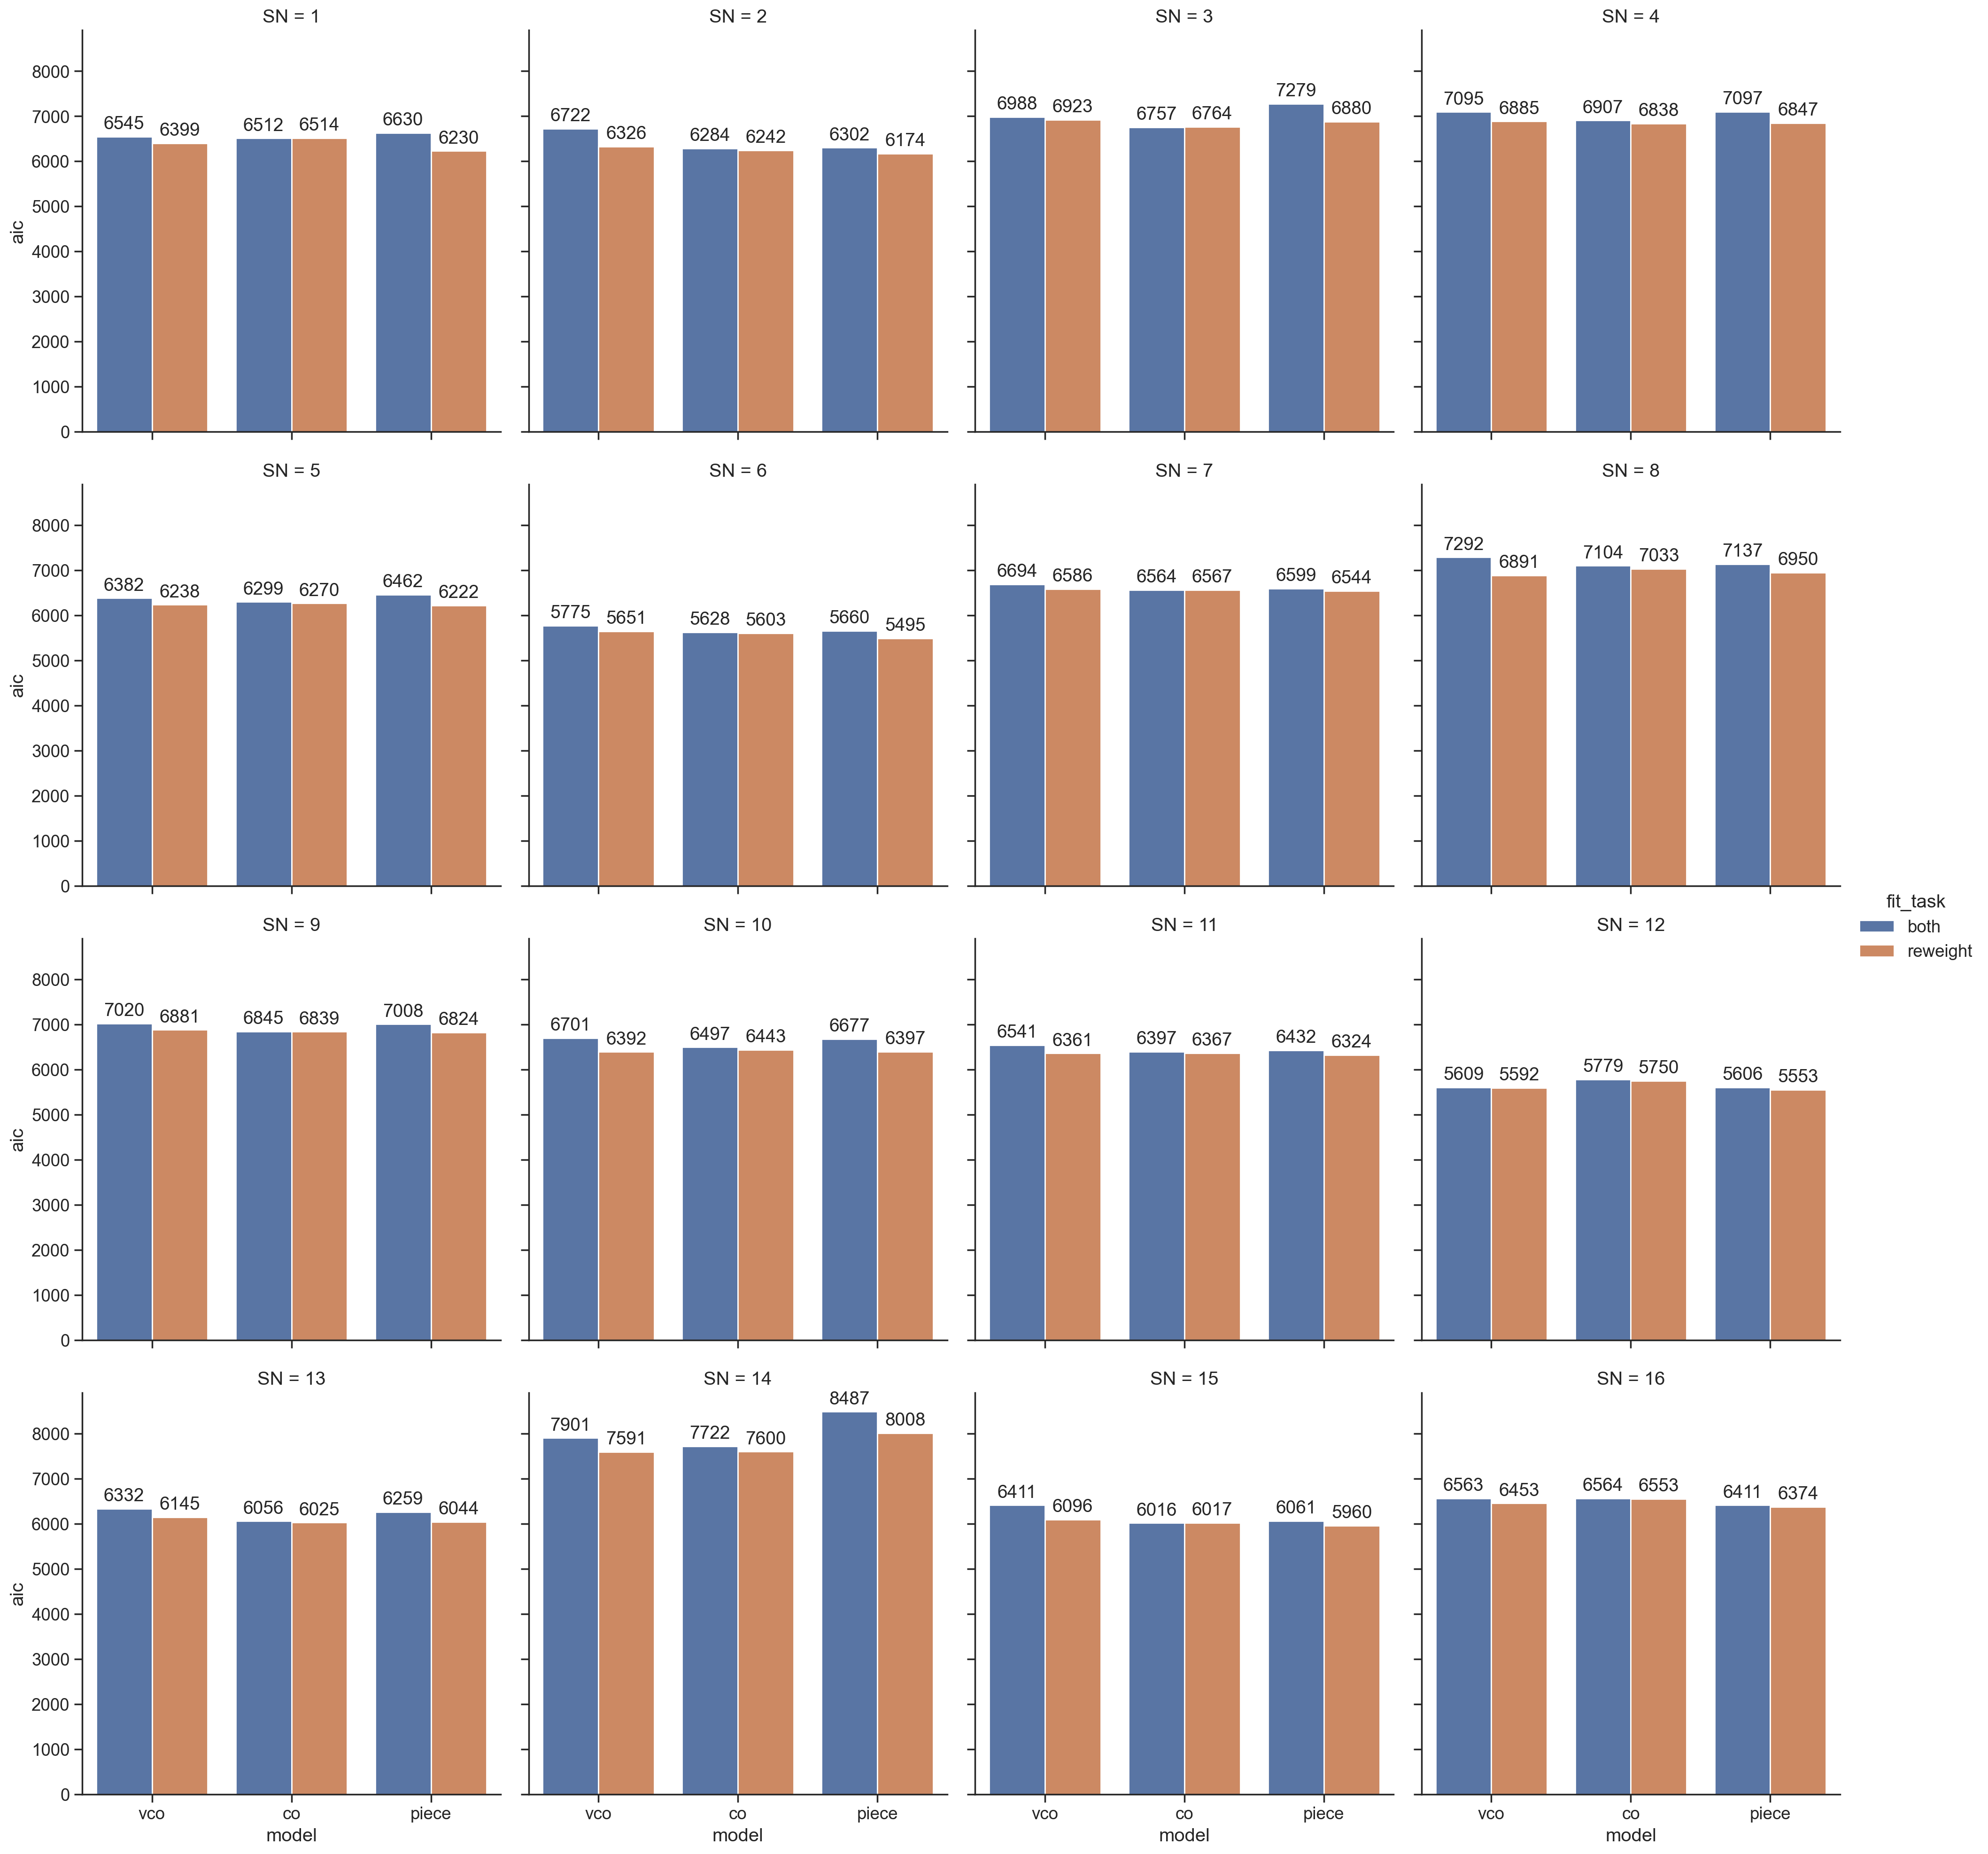

In [9]:
# Generate your grid (facets) of bar charts 
g = sns.catplot(
    kind="bar",
    data=df_compare,
    x="model",
    y="aic",
    hue="fit_task",
    col="SN",
    col_wrap=4,
    errorbar=None
)

# To print AIC value above corresponding bar: loop through every subplot created by grid
for ax in g.axes.flat:
    # Loop through each group of bars (e.g., different hue levels)
    for container in ax.containers:
        # Print the AIC value rounded to an integer above each bar
        ax.bar_label(container, fmt="%.0f", padding=3, fontsize=14)

plt.show()

In [10]:
# Count how many participants were best fit by each model
idx = df_compare.groupby("SN")["aic"].idxmin()
best = df_compare.loc[idx].reset_index(drop=True)
best[["model", "fit_task"]].value_counts()

model  fit_task
piece  reweight    10
vco    reweight     3
co     reweight     2
       both         1
Name: count, dtype: int64

In [11]:
# How many participants' adaptation best fit by each model
best_adapt_idx = fits_adapt.groupby(["SN"])["aic"].idxmin()
fits_adapt.loc[best_adapt_idx, "model"].value_counts()

model
co    16
Name: count, dtype: int64

In [12]:
# How many participants' SDT best fit by each model
best_sdt_idx = fits_sdt.groupby(["SN"])["aic"].idxmin()
fits_sdt.loc[best_sdt_idx, "model"].value_counts()

model
piece    15
vco       1
Name: count, dtype: int64

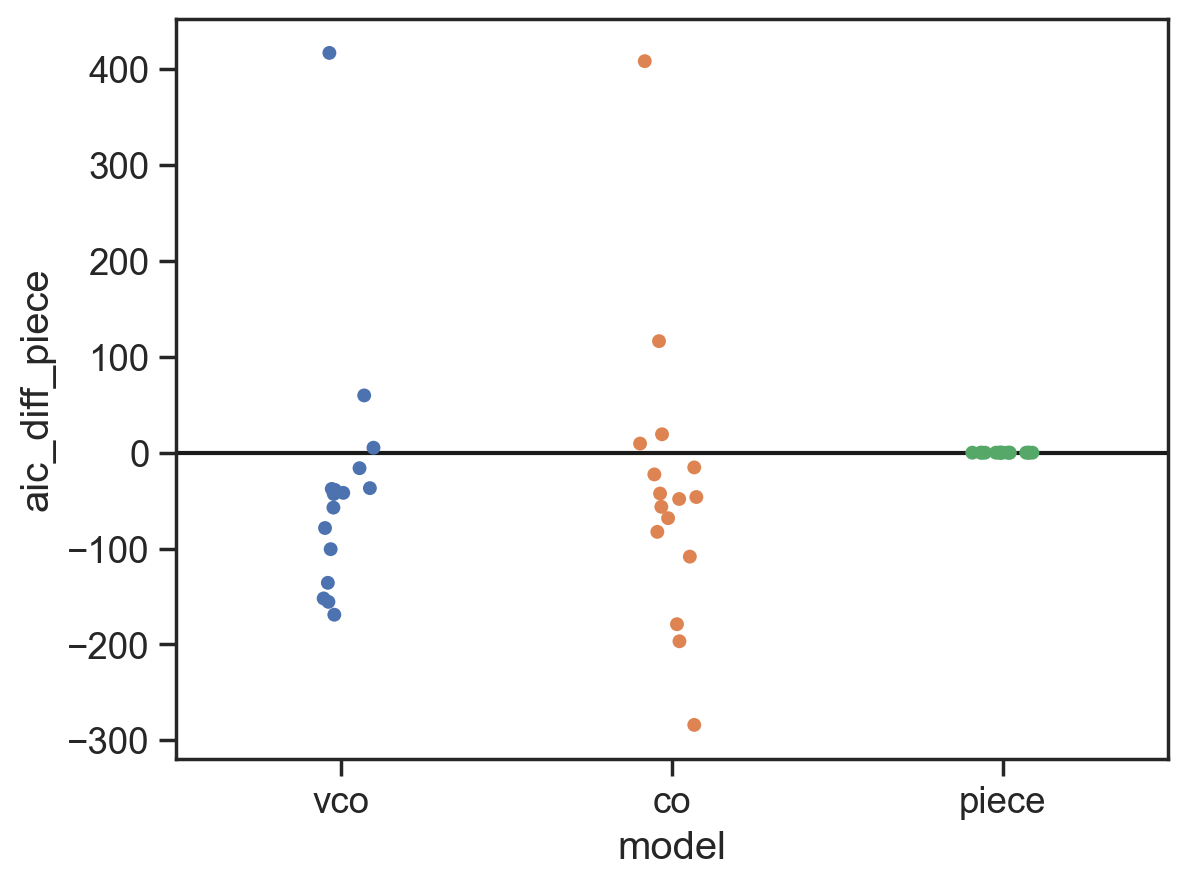

In [13]:
# Plot
fig, ax = plt.subplots()
# sns.pointplot(data=df_compare, x="model", y="aic_diff_piece", hue="model", ax=ax)
sns.stripplot(data=df_compare, x="model", y="aic_diff_piece", hue="model", ax=ax)
ax.axhline(color="k")
plt.show()